# TP01 - Etapa 02: Regras de Associação (Apriori)

**Objetivo:** Descobrir associações do tipo X → Y entre o perfil do candidato (sexo, UF, local), a modalidade de cota, o turno, a opção de curso e a faixa de nota no SiSU 2023.1.

## 0. Importação das Bibliotecas e Configuração Inicial

In [1]:
# Bibliotecas
import time                      # mede o tempo de cada execução do Apriori
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Apriori e geração de regras (mlxtend)
from mlxtend.frequent_patterns import apriori, association_rules

np.random.seed(42)

# Mostra mais colunas ao imprimir tabelas
pd.set_option("display.max_columns", 50)

# Caminho da base (mesmo dos outros notebooks; o Jupyter é aberto pela pasta notebooks/)
caminho = "../data/raw/chamada_regular_sisu_2023_1.csv"

## 1. Carregamento da base

A base completa tem ~2 milhões de linhas e 56 colunas. Para as regras de associação só precisamos de poucas colunas, então usamos `usecols` para economizar memória.

- Usamos `UF_CAMPUS` e não `UF_IES`: o campus é onde o aluno estuda de fato, e é o que comparamos com a UF do candidato (mesmo critério do notebook 03).

In [2]:
# Colunas que serão usadas nas regras (perfil, cota, turno, opção e notas)
colunas = [
    "SEXO", "UF_CANDIDATO", "UF_CAMPUS",
    "TP_COTA", "TIPO_MOD_CONCORRENCIA",
    "TURNO", "OPCAO",
    "NOTA_CANDIDATO",
    "NOTA_L", "NOTA_CH", "NOTA_CN", "NOTA_M", "NOTA_R",
]

# Separador '|', codificação latin1 e decimal com vírgula (igual ao notebook 03).
# TP_COTA tem tipos misturados, então é lida como texto (dtype=str).

df = pd.read_csv(
    caminho,
    sep="|",
    encoding="latin1",
    decimal=",",
    usecols=colunas,
    dtype={"TP_COTA": str},
)

print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
df.head()

Linhas: 2062815 | Colunas: 13


,UF_CAMPUS,TURNO,TP_COTA,TIPO_MOD_CONCORRENCIA,SEXO,UF_CANDIDATO,OPCAO,NOTA_L,NOTA_CH,NOTA_CN,NOTA_M,NOTA_R,NOTA_CANDIDATO
0,RJ,Noturno,NaN,A,M,RJ,1,601.3,605.3,615.3,663.2,920,713.64
1,RJ,Noturno,NaN,A,M,RJ,2,545.2,554.5,554.1,551.6,480,532.21
2,RJ,Noturno,NaN,A,M,RJ,1,593.5,645.9,623.4,719.7,860,722.27
3,RJ,Noturno,NaN,A,M,RJ,1,485.1,572.2,526.2,520.6,600,544.74
4,RJ,Noturno,NaN,A,M,RJ,1,631.3,604.8,621.1,673.1,580,628.25


In [3]:
# Quantidade e percentual de nulos por coluna
nulos = df.isnull().sum().to_frame("nulos")
nulos["%"] = (nulos["nulos"] / len(df) * 100).round(2)
display(nulos)

# Valores mais frequentes das colunas categóricas (para conhecer as categorias)
for col in ["SEXO", "TP_COTA", "TIPO_MOD_CONCORRENCIA", "TURNO", "OPCAO"]:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False).head(10).to_string())

,nulos,%
UF_CAMPUS,0,0.00
TURNO,0,0.00
TP_COTA,1129089,54.74
TIPO_MOD_CONCORRENCIA,0,0.00
SEXO,0,0.00
UF_CANDIDATO,0,0.00
OPCAO,0,0.00
NOTA_L,0,0.00
NOTA_CH,0,0.00
NOTA_CN,0,0.00



=== SEXO ===
SEXO
F    1283223
M     779592

=== TP_COTA ===
TP_COTA
NaN     1129089
PPI      482143
D        382387
PP        52344
PPID       7975
DD         5677
I          2314
PPD         886

=== TIPO_MOD_CONCORRENCIA ===
TIPO_MOD_CONCORRENCIA
L    933726
A    904906
B    117385
V    106798

=== TURNO ===
TURNO
Integral      1167709
Noturno        517904
Matutino       246759
Vespertino     120489
EaD              9954

=== OPCAO ===
OPCAO
1    1073024
2     989791


## 2. Tratamento de nulos e criação de `CANDIDATO_LOCAL`

- **Nulos em `TP_COTA` (54,74%):** o nulo ocorre exatamente quando a modalidade não é `L` (Lei de Cotas), então vira a categoria `"Indefinido"`. Remover essas linhas descartaria mais da metade da base e enviesaria as regras.
- **`CANDIDATO_LOCAL`:** `Mesma_UF` se a UF do candidato for igual à do campus, senão `Outra_UF`. `UF_CAMPUS` é removida depois, pois já está resumida nela.
- **Limitação:** há uma linha por candidatura (opção 1 e 2), então as regras descrevem candidaturas, e não pessoas.

In [4]:
# Confere os tipos: as notas precisam ser numéricas para a discretização
print(df.dtypes)

# Entende o que o nulo de TP_COTA significa, cruzando com a modalidade de concorrência
print(pd.crosstab(df["TP_COTA"].isna().rename("TP_COTA_nulo"),
                  df["TIPO_MOD_CONCORRENCIA"]))

# Nulos de TP_COTA viram uma categoria própria, sem perder linhas
df["TP_COTA"] = df["TP_COTA"].fillna("Indefinido")

# Cria CANDIDATO_LOCAL: o candidato é da mesma UF do campus ou de outra?
df["CANDIDATO_LOCAL"] = np.where(df["UF_CANDIDATO"] == df["UF_CAMPUS"],
                                 "Mesma_UF", "Outra_UF")

# UF_CAMPUS já está resumida em CANDIDATO_LOCAL
df = df.drop(columns=["UF_CAMPUS"])

# Confere o resultado
print(df["CANDIDATO_LOCAL"].value_counts(normalize=True).round(3))
print("Nulos restantes:", df.isnull().sum().sum())

UF_CAMPUS                    str
TURNO                        str
TP_COTA                      str
TIPO_MOD_CONCORRENCIA        str
SEXO                         str
UF_CANDIDATO                 str
OPCAO                      int64
NOTA_L                   float64
NOTA_CH                  float64
NOTA_CN                  float64
NOTA_M                   float64
NOTA_R                     int64
NOTA_CANDIDATO           float64
dtype: object
TIPO_MOD_CONCORRENCIA       A       B       L       V
TP_COTA_nulo                                         
False                       0       0  933726       0
True                   904906  117385       0  106798
CANDIDATO_LOCAL
Mesma_UF    0.801
Outra_UF    0.199
Name: proportion, dtype: float64
Nulos restantes: 0


   ## 3. Amostragem

   A base tem ~2 milhões de candidaturas. Como vamos testar vários valores de suporte e confiança, usamos uma amostra aleatória de 150.000 linhas (`random_state=42`), que mantém cada teste em segundos (15 s no pior caso). Com `min_support = 0,01`, cada itemset tem pelo menos 1.500 transações. A comparação abaixo confirma que as proporções foram preservadas (diferenças de no máximo 0,002).

In [5]:
# Amostra aleatória reprodutível (random_state=42, como exige o enunciado)
N_AMOSTRA = 150_000
df_amostra = df.sample(n=N_AMOSTRA, random_state=42).reset_index(drop=True)
print("Shape da amostra:", df_amostra.shape)

# A amostra preservou as proporções da base completa? (diferenças devem ser pequenas)
for col in ["SEXO", "TIPO_MOD_CONCORRENCIA", "TURNO", "CANDIDATO_LOCAL"]:
    comparacao = pd.DataFrame({
        "base_completa": df[col].value_counts(normalize=True),
        "amostra": df_amostra[col].value_counts(normalize=True),
    }).round(3)
    print(f"\n=== {col} ===")
    print(comparacao.to_string())

# E a nota? Média e desvio devem ser parecidos
print("\nNOTA_CANDIDATO:")
print(pd.DataFrame({"base_completa": df["NOTA_CANDIDATO"].describe(),
                    "amostra": df_amostra["NOTA_CANDIDATO"].describe()}).round(2))

Shape da amostra: (150000, 13)

=== SEXO ===
      base_completa  amostra
SEXO                        
F             0.622    0.622
M             0.378    0.378

=== TIPO_MOD_CONCORRENCIA ===
                       base_completa  amostra
TIPO_MOD_CONCORRENCIA                        
L                              0.453    0.452
A                              0.439    0.440
B                              0.057    0.056
V                              0.052    0.051

=== TURNO ===
            base_completa  amostra
TURNO                             
Integral            0.566    0.566
Noturno             0.251    0.251
Matutino            0.120    0.119
Vespertino          0.058    0.059
EaD                 0.005    0.005

=== CANDIDATO_LOCAL ===
                 base_completa  amostra
CANDIDATO_LOCAL                        
Mesma_UF                 0.801      0.8
Outra_UF                 0.199      0.2

NOTA_CANDIDATO:
       base_completa    amostra
count     2062815.00  150000.00
mean  

## 4. Discretização da nota em 3 categorias

Transformamos `NOTA_CANDIDATO` em `Nota_Baixa`, `Nota_Media` e `Nota_Alta` por **tercis (`pd.qcut`)**: cada categoria fica com ~33% das linhas, então todas têm suporte alto o bastante para o Apriori. Usamos só a nota geral, pois as notas por área são muito correlacionadas e gerariam regras óbvias.

Pontos de corte (qcut): [ 96.   539.58 617.66 955.08]
Pontos de corte (cut):  [ 95.14 382.36 668.72 955.08]


,qcut (tercis),cut (largura igual),% qcut,% cut
Nota_Baixa,50011,643,33.3,0.4
Nota_Media,49995,124827,33.3,83.2
Nota_Alta,49994,24530,33.3,16.4


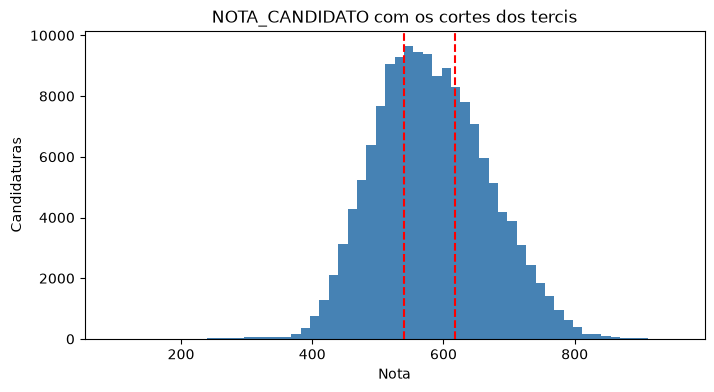

In [6]:
# Rótulos das 3 categorias
rotulos = ["Nota_Baixa", "Nota_Media", "Nota_Alta"]

# Tercis: qcut divide em 3 grupos de mesmo tamanho; retbins=True devolve os pontos de corte
df_amostra["NOTA"], cortes = pd.qcut(
    df_amostra["NOTA_CANDIDATO"], q=3, labels=rotulos, retbins=True
)

# Para comparar: intervalos de mesma largura (pd.cut)
nota_larg_igual, cortes_larg = pd.cut(
    df_amostra["NOTA_CANDIDATO"], bins=3, labels=rotulos, retbins=True
)

# Tabela comparando as duas técnicas (corte e quantidade por categoria)
comparacao = pd.DataFrame({
    "qcut (tercis)": df_amostra["NOTA"].value_counts(),
    "cut (largura igual)": nota_larg_igual.value_counts(),
}).loc[rotulos]
comparacao["% qcut"] = (comparacao["qcut (tercis)"] / len(df_amostra) * 100).round(1)
comparacao["% cut"] = (comparacao["cut (largura igual)"] / len(df_amostra) * 100).round(1)

print("Pontos de corte (qcut):", cortes.round(2))
print("Pontos de corte (cut): ", cortes_larg.round(2))
display(comparacao)

# Histograma com os cortes dos tercis (linhas tracejadas)
plt.figure(figsize=(8, 4))
plt.hist(df_amostra["NOTA_CANDIDATO"], bins=60, color="steelblue")
for c in cortes[1:-1]:
    plt.axvline(c, color="red", linestyle="--")
plt.title("NOTA_CANDIDATO com os cortes dos tercis")
plt.xlabel("Nota")
plt.ylabel("Candidaturas")
plt.show()

**Resultado:** cortes em 539,58 e 617,66, com ~50 mil linhas por categoria. Com `pd.cut` (intervalos iguais) ficaria 0,4% / 83,2% / 16,4%: `Nota_Baixa` (643 linhas) seria eliminada pelo Apriori e `Nota_Media` (83%) deixaria o lift quase sem variação.

## 5. Binarização (One-Hot Encoding)

Cada coluna categórica vira itens `coluna=valor` (ex.: `SEXO=F`) numa matriz True/False, em que cada linha é uma candidatura. `OPCAO` vira texto para ser tratada como categoria, e as notas contínuas ficam de fora.

In [7]:
# Colunas que viram itens (as do enunciado + a nota discretizada)
colunas_apriori = [
    "SEXO", "UF_CANDIDATO", "CANDIDATO_LOCAL",
    "TP_COTA", "TIPO_MOD_CONCORRENCIA",
    "TURNO", "OPCAO", "NOTA",
]

# Tudo vira texto (OPCAO é int e NOTA é categoria do pandas)
df_cat = df_amostra[colunas_apriori].astype(str)

# One-Hot: cada coluna vira itens "coluna=valor" com True/False
matriz = pd.get_dummies(df_cat, prefix_sep="=", dtype=bool)

print("Shape da matriz transacional:", matriz.shape)
print("Exemplo de itens:", list(matriz.columns[:8]))

# Suporte de cada item = proporção de linhas em que ele é True
suporte_itens = matriz.mean().sort_values(ascending=False)

print("\n10 itens mais frequentes:")
print(suporte_itens.head(10).round(3).to_string())

print("\n10 itens menos frequentes:")
print(suporte_itens.tail(10).round(4).to_string())

# Quantos itens sobrevivem a cada suporte mínimo candidato
for ms in [0.10, 0.05, 0.02, 0.01]:
    print(f"Itens com suporte >= {ms}: {(suporte_itens >= ms).sum()} de {len(suporte_itens)}")

Shape da matriz transacional: (150000, 53)
Exemplo de itens: ['SEXO=F', 'SEXO=M', 'UF_CANDIDATO=AC', 'UF_CANDIDATO=AL', 'UF_CANDIDATO=AM', 'UF_CANDIDATO=AP', 'UF_CANDIDATO=BA', 'UF_CANDIDATO=CE']

10 itens mais frequentes:
CANDIDATO_LOCAL=Mesma_UF    0.800
SEXO=F                      0.622
TURNO=Integral              0.566
TP_COTA=Indefinido          0.548
OPCAO=1                     0.521
OPCAO=2                     0.479
TIPO_MOD_CONCORRENCIA=L     0.452
TIPO_MOD_CONCORRENCIA=A     0.440
SEXO=M                      0.378
NOTA=Nota_Baixa             0.333

10 itens menos frequentes:
UF_CANDIDATO=AC    0.0079
UF_CANDIDATO=AP    0.0062
TURNO=EaD          0.0050
UF_CANDIDATO=TO    0.0040
TP_COTA=PPID       0.0037
UF_CANDIDATO=RO    0.0032
TP_COTA=DD         0.0026
UF_CANDIDATO=RR    0.0022
TP_COTA=I          0.0011
TP_COTA=PPD        0.0004
Itens com suporte >= 0.1: 19 de 53
Itens com suporte >= 0.05: 26 de 53
Itens com suporte >= 0.02: 36 de 53
Itens com suporte >= 0.01: 43 de 53


**Resultado:** matriz de 150.000 × 53 itens. Com `min_support = 0,01`, 43 itens sobrevivem; somem UFs pequenas, `TURNO=EaD` e cotas raras (`PPID`, `DD`, `I`, `PPD`), que não aparecerão em nenhuma regra.

## 6. Apriori: calibração do suporte mínimo

Testamos 0,10; 0,05; 0,02 e 0,01 e comparamos o nº de itemsets, o tamanho do maior e o tempo.

In [8]:
# Valores de suporte mínimo a testar (do mais alto ao mais baixo)
suportes = [0.10, 0.05, 0.02, 0.01]

resultados = []          # linhas da tabela de calibração
itemsets_por_suporte = {}  # guarda os itemsets de cada rodada para usar depois

for ms in suportes:
    inicio = time.time()
    itens = apriori(matriz, min_support=ms, use_colnames=True)
    tempo = time.time() - inicio

    # Tamanho de cada itemset (quantidade de itens)
    tamanhos = itens["itemsets"].apply(len)

    resultados.append({
        "min_support": ms,
        "n_itemsets": len(itens),
        "maior_itemset": tamanhos.max(),
        "tempo_s": round(tempo, 1),
    })
    itemsets_por_suporte[ms] = itens
    print(f"min_support={ms}: {len(itens)} itemsets em {tempo:.1f}s")

# Tabela final de calibração
tabela_suporte = pd.DataFrame(resultados)
display(tabela_suporte)

min_support=0.1: 246 itemsets em 0.2s
min_support=0.05: 665 itemsets em 0.5s
min_support=0.02: 1958 itemsets em 1.4s
min_support=0.01: 4123 itemsets em 3.9s


,min_support,n_itemsets,maior_itemset,tempo_s
0,0.10,246,5,0.2
1,0.05,665,6,0.5
2,0.02,1958,7,1.4
3,0.01,4123,7,3.9


**Escolha: `min_support = 0,01`** (4.123 itemsets em ~15 s). O custo é baixo, o crescimento é regular e cobre mais itens (43, contra 36 em 0,02). 1% de 150.000 são 1.500 candidaturas, ainda sólido. O excesso de regras é tratado depois pelos filtros.

## 7. Regras de associação: calibração da confiança mínima

Com os itemsets de `min_support = 0,01`, testamos confiança mínima de 0,5; 0,6 e 0,7. Itens muito frequentes (ex.: `Mesma_UF`, 80%) dão confiança alta por acaso, por isso o **lift** é o filtro principal na próxima etapa.

In [9]:
# Itemsets escolhidos na calibração anterior
itemsets_escolhidos = itemsets_por_suporte[0.01]
n_transacoes = len(matriz)

# Função que funciona em versões novas e antigas do mlxtend
def gerar_regras(itens, conf_min):
    try:
        return association_rules(itens, num_itemsets=n_transacoes,
                                 metric="confidence", min_threshold=conf_min)
    except TypeError:  # versões antigas não têm num_itemsets
        return association_rules(itens, metric="confidence", min_threshold=conf_min)

# Testa as confianças mínimas e resume cada resultado
resultados_conf = []
regras_por_conf = {}

for conf in [0.5, 0.6, 0.7]:
    inicio = time.time()
    regras = gerar_regras(itemsets_escolhidos, conf)
    tempo = time.time() - inicio

    resultados_conf.append({
        "min_confidence": conf,
        "n_regras": len(regras),
        "n_com_lift>1": (regras["lift"] > 1).sum(),
        "lift_maximo": round(regras["lift"].max(), 2),
        "tempo_s": round(tempo, 1),
    })
    regras_por_conf[conf] = regras

tabela_conf = pd.DataFrame(resultados_conf)
display(tabela_conf)

,min_confidence,n_regras,n_com_lift>1,lift_maximo,tempo_s
0,0.5,10453,8496,12.37,0.1
1,0.6,6188,5495,12.37,0.1
2,0.7,3684,3331,4.15,0.1


**Escolha: `min_confidence = 0,6`.** Com 0,7 o lift máximo cai de 12,37 para 4,15 (perdemos as regras mais distintivas); com 0,5 sobram muitas regras fracas (quase 2 mil com lift ≤ 1).

## 8. Filtro por lift e remoção de regras triviais

Partindo de `min_confidence = 0,6`:
1. **Lift > 1:** o antecedente aumenta a chance do consequente.
2. **Triviais:** `TP_COTA` é nulo exatamente quando a modalidade não é `L`, então descartamos regras que usam `TP_COTA` e `TIPO_MOD_CONCORRENCIA` juntas.
3. **Uma regra por itemset:** o lift é simétrico, então mantemos a de maior confiança para não repetir o mesmo padrão.

In [10]:
# Regras com a confiança mínima escolhida
regras = regras_por_conf[0.6].copy()
n_inicial = len(regras)

# 1) Lift > 1
regras = regras[regras["lift"] > 1].copy()
n_lift = len(regras)

# Colunas de origem de cada item ("TP_COTA=PPI" -> "TP_COTA")
def colunas_do_conjunto(conjunto):
    return {item.split("=")[0] for item in conjunto}

# 2) Remove regras que usam TP_COTA e TIPO_MOD_CONCORRENCIA ao mesmo tempo
par_redundante = {"TP_COTA", "TIPO_MOD_CONCORRENCIA"}
usa_as_duas = regras.apply(
    lambda r: par_redundante <= colunas_do_conjunto(r["antecedents"] | r["consequents"]),
    axis=1,
)
regras = regras[~usa_as_duas].copy()
n_sem_triviais = len(regras)

# 3) Uma regra por conjunto de itens: a de maior confiança
regras["itemset"] = regras.apply(lambda r: r["antecedents"] | r["consequents"], axis=1)
melhor = regras.groupby("itemset")["confidence"].idxmax()
regras_finais = regras.loc[melhor].sort_values("lift", ascending=False).reset_index(drop=True)

# Resumo de quantas regras sobraram em cada filtro
print(f"Regras com min_confidence=0.6:        {n_inicial}")
print(f"Depois do filtro lift > 1:            {n_lift}")
print(f"Depois de remover triviais:           {n_sem_triviais}")
print(f"Depois de 1 regra por itemset (final): {len(regras_finais)}")

# Deixa a regra legível: "A, B" -> "C"
def texto(conjunto):
    return ", ".join(sorted(conjunto))

tabela_top = regras_finais.head(10).copy()
tabela_top["antecedente"] = tabela_top["antecedents"].apply(texto)
tabela_top["consequente"] = tabela_top["consequents"].apply(texto)

pd.set_option("display.max_colwidth", 80)
display(tabela_top[["antecedente", "consequente", "support", "confidence", "lift"]].round(3))

Regras com min_confidence=0.6:        6188
Depois do filtro lift > 1:            5495
Depois de remover triviais:           2258
Depois de 1 regra por itemset (final): 1689


,antecedente,consequente,support,confidence,lift
0,"OPCAO=1, TIPO_MOD_CONCORRENCIA=B, TURNO=Integral",NOTA=Nota_Alta,0.013,0.740,2.220
1,"TIPO_MOD_CONCORRENCIA=B, TURNO=Integral",NOTA=Nota_Alta,0.023,0.729,2.188
2,"SEXO=F, TIPO_MOD_CONCORRENCIA=B, TURNO=Integral",NOTA=Nota_Alta,0.014,0.719,2.157
3,"SEXO=M, TIPO_MOD_CONCORRENCIA=B",NOTA=Nota_Alta,0.015,0.665,1.996
4,"OPCAO=1, TIPO_MOD_CONCORRENCIA=B",NOTA=Nota_Alta,0.020,0.662,1.987
5,"OPCAO=1, SEXO=F, TIPO_MOD_CONCORRENCIA=B",NOTA=Nota_Alta,0.012,0.656,1.967
6,TIPO_MOD_CONCORRENCIA=B,NOTA=Nota_Alta,0.037,0.651,1.954
7,"SEXO=F, TIPO_MOD_CONCORRENCIA=B",NOTA=Nota_Alta,0.021,0.641,1.925
8,"OPCAO=2, TIPO_MOD_CONCORRENCIA=B",NOTA=Nota_Alta,0.017,0.638,1.915
9,"CANDIDATO_LOCAL=Outra_UF, NOTA=Nota_Alta, OPCAO=1, UF_CANDIDATO=SP",TIPO_MOD_CONCORRENCIA=A,0.011,0.750,1.702


**Resultado:** 6.188 → 5.495 (lift > 1) → 2.258 (sem triviais) → 1.689 (uma por itemset). O Top 10 ainda é quase só variações de `TIPO_MOD_CONCORRENCIA=B → Nota_Alta` com itens extras no antecedente, tratado a seguir.

### 8.1 Remoção de regras redundantes

Uma regra complexa só é útil se melhorar a confiança de uma regra mais simples. Mantemos `X → Y` só se sua confiança superar a da melhor regra `X' → Y` (com `X'` subconjunto de `X`) em pelo menos **0,02**. Limitamos também o antecedente a **3 itens**, para facilitar a interpretação.

In [11]:
from itertools import combinations

MIN_MELHORIA = 0.02   # a regra complexa precisa ganhar 2 p.p. de confiança
MAX_ANTECEDENTE = 3   # no máximo 3 itens no "se"

# Dicionário itemset -> suporte (os subconjuntos de itemsets frequentes também estão aqui)
suporte = dict(zip(itemsets_escolhidos["itemsets"], itemsets_escolhidos["support"]))

# Quanto a regra melhora a confiança da melhor regra mais simples (mesmo consequente)
def melhoria(regra):
    ant, con = regra["antecedents"], regra["consequents"]
    melhor_simples = 0.0
    for k in range(1, len(ant)):                 # subconjuntos próprios e não vazios
        for sub in combinations(ant, k):
            sub = frozenset(sub)
            conf_sub = suporte[sub | con] / suporte[sub]
            melhor_simples = max(melhor_simples, conf_sub)
    return regra["confidence"] - melhor_simples  # antecedente de 1 item: melhoria = confiança

regras["melhoria"] = regras.apply(melhoria, axis=1)
regras["tam_ant"] = regras["antecedents"].apply(len)

# Aplica os dois filtros e conta quantas regras sobram em cada um
sem_red = regras[regras["melhoria"] >= MIN_MELHORIA]
curtas = sem_red[sem_red["tam_ant"] <= MAX_ANTECEDENTE].copy()
print(f"Antes: {len(regras)} | sem redundantes: {len(sem_red)} | antecedente <= {MAX_ANTECEDENTE}: {len(curtas)}")

# Uma regra por itemset (a de maior confiança), ordenada por lift
melhor = curtas.groupby("itemset")["confidence"].idxmax()
regras_finais = curtas.loc[melhor].sort_values("lift", ascending=False).reset_index(drop=True)
print(f"Regras finais: {len(regras_finais)}")

# Top 10 legível
tabela_top = regras_finais.head(10).copy()
tabela_top["antecedente"] = tabela_top["antecedents"].apply(texto)
tabela_top["consequente"] = tabela_top["consequents"].apply(texto)
display(tabela_top[["antecedente", "consequente", "support", "confidence", "lift", "melhoria"]].round(3))

Antes: 2258 | sem redundantes: 218 | antecedente <= 3: 194
Regras finais: 187


,antecedente,consequente,support,confidence,lift,melhoria
0,"NOTA=Nota_Alta, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.022,0.619,3.097,0.067
1,"TP_COTA=Indefinido, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.025,0.618,3.093,0.069
2,"TIPO_MOD_CONCORRENCIA=A, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.024,0.604,3.026,0.070
3,"TIPO_MOD_CONCORRENCIA=B, TURNO=Integral","CANDIDATO_LOCAL=Mesma_UF, NOTA=Nota_Alta",0.021,0.657,2.713,0.056
4,TIPO_MOD_CONCORRENCIA=B,"CANDIDATO_LOCAL=Mesma_UF, NOTA=Nota_Alta",0.034,0.602,2.484,0.602
5,"TIPO_MOD_CONCORRENCIA=B, TURNO=Integral",NOTA=Nota_Alta,0.023,0.729,2.188,0.078
6,TIPO_MOD_CONCORRENCIA=B,NOTA=Nota_Alta,0.037,0.651,1.954,0.651
7,"TIPO_MOD_CONCORRENCIA=A, TURNO=Integral, UF_CANDIDATO=SP",NOTA=Nota_Alta,0.025,0.639,1.917,0.067
8,"TP_COTA=Indefinido, TURNO=Integral, UF_CANDIDATO=SP",NOTA=Nota_Alta,0.026,0.636,1.909,0.067
9,"CANDIDATO_LOCAL=Outra_UF, TIPO_MOD_CONCORRENCIA=A, TURNO=Integral",NOTA=Nota_Alta,0.042,0.619,1.858,0.060


**Resultado:** 2.258 → 218 sem redundantes → 194 com antecedente ≤ 3 → 187 regras finais. Para antecedentes de 1 item não há regra mais simples, então a `melhoria` é igual à confiança.

### 8.2 Exclusão da modalidade B (bonificação regional)

Consultamos a descrição e o bônus de cada modalidade na base completa (lendo só 3 colunas).

In [12]:
# Lê só 3 colunas da base inteira para entender o que significa cada modalidade
chk = pd.read_csv(
    caminho, sep="|", encoding="latin1", decimal=",",
    usecols=["TIPO_MOD_CONCORRENCIA", "MOD_CONCORRENCIA", "PERCENTUAL_BONUS"],
)

# Descrição textual mais comum de cada tipo de modalidade
print("Descrição (MOD_CONCORRENCIA) mais comum por tipo:")
for tipo, grupo in chk.groupby("TIPO_MOD_CONCORRENCIA"):
    print(f"\n{tipo}:")
    print(grupo["MOD_CONCORRENCIA"].value_counts().head(3).to_string())

# Bônus por tipo de modalidade: se B tiver bônus > 0, a nota dele já inclui o bônus
print("\nPERCENTUAL_BONUS por tipo:")
print(chk.groupby("TIPO_MOD_CONCORRENCIA")["PERCENTUAL_BONUS"].describe().round(2))

Descrição (MOD_CONCORRENCIA) mais comum por tipo:

A:
MOD_CONCORRENCIA
Ampla concorrência    904906

B:
MOD_CONCORRENCIA
B5825: Candidatos BE - Candidatos que atendam aos critérios estabelecidos pela Resolução nº 43/2021 CONSEPE /UFPB e suas alterações para bonificação de inclusão estadual: para os candidatos que pleiteiam vaga em cursos de graduação da UFPB, via SiSU, que residem e comprovem residência no Estado da Paraíba e tenham estudado integralmente o Ensino Médio em escolas regulares, públicas e/ou privadas, ou tenham obtido o certificado de Ensino Médio pela Educação de Jovens e Adultos (EJA), ou pelo Exame Nacional para Certificação de Competências para Jovens e Adultos (ENCCEJA) no Estado da Paraíba.    14350
Candidatos que residam e tenham cursado todo o ensino médio em instituições (da rede pública ou privada) de Ensino do Estado da Paraíba (Lei nº 12.122 de 09 de Novembro de 2021)                                                                                              

**Modalidades:** `A` ampla concorrência; `L` Lei de Cotas; `B` bonificação regional (ex.: UFPB, UFAM); `V` ações afirmativas próprias das instituições. Só a `B` tem bônus (média de 12,4% na nota, de 3% a 20%) e exige residir no estado da instituição, então `Mesma_UF` e `Nota_Alta` aparecem em parte por construção.

**Decisão:** removemos as regras com `B`, pois descrevem o desenho da política, e não o comportamento dos candidatos.

In [13]:
# Remove regras com a modalidade B (bonificação regional): refletem o desenho da política
sem_b = curtas[~curtas["itemset"].apply(lambda s: "TIPO_MOD_CONCORRENCIA=B" in s)]
print(f"Antes: {len(curtas)} | sem B: {len(sem_b)}")

# Uma regra por itemset (a de maior confiança), ordenada por lift
melhor = sem_b.groupby("itemset")["confidence"].idxmax()
regras_finais = sem_b.loc[melhor].sort_values("lift", ascending=False).reset_index(drop=True)

# Top 5 de maior lift
top5 = regras_finais.head(5).copy()
top5["antecedente"] = top5["antecedents"].apply(texto)
top5["consequente"] = top5["consequents"].apply(texto)
display(top5[["antecedente", "consequente", "support", "confidence", "lift"]].round(3))

Antes: 194 | sem B: 187


,antecedente,consequente,support,confidence,lift
0,"NOTA=Nota_Alta, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.022,0.619,3.097
1,"TP_COTA=Indefinido, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.025,0.618,3.093
2,"TIPO_MOD_CONCORRENCIA=A, TURNO=Integral, UF_CANDIDATO=SP",CANDIDATO_LOCAL=Outra_UF,0.024,0.604,3.026
3,"TIPO_MOD_CONCORRENCIA=A, TURNO=Integral, UF_CANDIDATO=SP",NOTA=Nota_Alta,0.025,0.639,1.917
4,"TP_COTA=Indefinido, TURNO=Integral, UF_CANDIDATO=SP",NOTA=Nota_Alta,0.026,0.636,1.909


## 9. Top 5 regras de maior Lift

Referência na amostra: 19,9% das candidaturas são `Outra_UF` e 33,3% são `Nota_Alta`. O lift diz quantas vezes a regra supera essa taxa-base.

1. **SP + nota alta + integral → outra UF (lift 3,10; confiança 61,9%).** Paulistas com nota alta em curso integral vão para campi fora de SP com mais de 3 vezes a frequência geral. Para quem concorre ao SiSU, vale considerar desde o início vagas em outros estados e o custo de mudança e moradia. Hipótese não testada: menor oferta de vagas via SiSU em SP.
2. **SP + sem cota da Lei + integral → outra UF (lift 3,09; 61,8%).** O mesmo padrão, com pouca dependência de nota ou cota: o que mais pesa é ser de SP e escolher curso integral
3. **SP + ampla concorrência + integral → outra UF (lift 3,03; 60,4%).** As regras 1 a 3 são variações da mesma ideia (`SP + Integral`); o terceiro item muda o lift só de 3,03 a 3,10.
4. **SP + ampla concorrência + integral → nota alta (lift 1,92; 63,9%).** Esse recorte tem 63,9% dos candidatos no terço superior de notas (33,3% no geral), então a disputa por essas vagas é mais acirrada.
5. **SP + sem cota da Lei + integral → nota alta (lift 1,91; 63,6%).** Praticamente a regra 4, pois `Indefinido` é ~80% ampla concorrência.

## 10. Conclusão

**Processo:** amostra de 150 mil candidaturas (`random_state=42`), nota em tercis, 53 itens, `min_support = 0,01` (4.123 itemsets) e `min_confidence = 0,6` (6.188 regras). Os filtros (lift > 1, sem triviais, sem redundantes, sem modalidade `B`) deixaram 187 regras.

**Resultado:** os maiores lifts giram em torno do candidato de SP em curso integral: mais de 3 vezes a chance geral de concorrer a um campus fora de SP (lift ~3,1) e, em ampla concorrência, maior chance de nota alta (lift ~1,9).

**Limitações:** uma linha por candidatura (as regras descrevem candidaturas, e não pessoas); tercis relativos a esta amostra; regras mostram co-ocorrência, e não causa; itens com menos de 1% de suporte e a modalidade `B` ficam de fora.